# Phase 1 – Exploratory Data Analysis (EDA)
## 1.1 Basic Description of the Data and Its Characteristics

In this section, we perform an initial exploratory data analysis of the dataset. The goal is to understand the underlying structure of the data, inspect individual feature distributions, identify pairwise relationships and dependencies, examine potential predictors for the target variable, and outline our initial strategy for the modeling phase.

We use these basic pandas, matplotlib and seaborn methods on dataset 002. Cleaning and statistical tests belong to subsequent sections and are not performed here.

First, let's inspect the raw content of the files to identify potential formatting issues:

In [2]:
from pathlib import Path

for filename in ['units.csv', 'gateways.csv', 'readings.csv']:
    print(f"--- {filename} ---")
    with (Path('002') / filename).open(encoding='utf-8') as file:
        for _, line in zip(range(5), file):
            print(line.rstrip())

--- units.csv ---
classDuty,id_depot,id_unit,last_overhaul,owner_operator,number_serial,serviceHours,installRegion,model_code,fleetCode
med,55,1,2023-10-06,Paiva S/A,GR-8858-77621,24700.40000,Beeskow,XC-7,FB
normal,70,2,2024-05-08,Ackermann GmbH,XD-2690-10343,24212.40000,Glennberg,APU-12,FC
3,112,3,"09/08/2021, 00:00:00",Carneiro,IH-3115-90470,11335.30000,East Shane,APU-12,FB
heavy,91,4,"07/15/2023, 00:00:00",Leite Paiva S.A.,KC-6991-40779,24208.00000,Ermesinde,APU-12,FC
--- gateways.csv ---
firmwareVersion;Vendor;mac_address;gatewayId;hardwareModel;id_depot;date_install;Technician;id_unit
v3.4.1;Gaspar;14:e2:b6:5b:d3:23;GW-00000;GWX-100;37;2022/03/25;Sylke Matthäi B.Sc.;1732
v2.7.0;Smith Group;49:ef:4c:12:57:66;GW-00001;GWX-300;49;2024-02-24;David Garrett;1663
v3.4.1;Johnson, Cox and Rivers;54:2c:85:df:29:58;GW-00002;GWX-100;35;06/20/2024, 00:00:00;Gerda Schuchhardt-Wagenknecht;793
v2.7.0;Klemm;d5:bd:73:60:04:73;GW-00003;GWX-300;59;2023-04-29;Constança Pires;948
--- readings.csv ---
i

The files use different delimiters: units.csv - commas, gateways.csv - semicolons, and readings.csv - tabs. Each file needs the correct separator when loading it with pandas.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

file_configs = {
    "units": {"path": "002/units.csv", "sep": ","},
    "gateways": {"path": "002/gateways.csv", "sep": ";"},
    "readings": {"path": "002/readings.csv", "sep": "\t"}
}

We store the file paths and separators in a dictionary so that all three files can be loaded consistently.

In [4]:
data_frames = {}
loaded_count = 0

for name, cfg in file_configs.items():
    if os.path.exists(cfg["path"]):
        data_frames[name] = pd.read_csv(cfg["path"], sep=cfg["sep"], encoding='utf-8', on_bad_lines='error')
        loaded_count += 1
    else:
        raise FileNotFoundError(cfg["path"])

if loaded_count == 3:
    print("OK. Successful loading. All files are ready.")
else:
    print("Not all files were found!")

units = data_frames.get("units")
gateways = data_frames.get("gateways")
readings = data_frames.get("readings")

OK. Successful loading. All files are ready.


In [5]:
file_summary = pd.DataFrame([
    {'file': name + '.csv', 'rows': df.shape[0], 'attributes': df.shape[1]}
    for name, df in data_frames.items()
])
display(file_summary)

,file,rows,attributes
0,units.csv,2000,10
1,gateways.csv,16000,9
2,readings.csv,14476,15


### (A) Structure of the Data

In this section, we examine the structural characteristics of the dataset. This includes verifying the number of files, their formats, how they relate to each other, the total number of records, the number of attributes, and their respective data types.

In [6]:
for name, df in data_frames.items():
    print("-" *7 + f" File : {name}.csv " + "-" *7)
    print(f"Number of records: {df.shape[0]}")
    print(f"Number of attributes: {df.shape[1]}")
    print("\nColumns and Data Types:")
    df.info()
    display(df.dtypes)
    print("\nFirst 3 rows:")
    display(df.head(3))

------- File : units.csv -------
Number of records: 2000
Number of attributes: 10

Columns and Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   classDuty       2000 non-null   str    
 1   id_depot        2000 non-null   int64  
 2   id_unit         2000 non-null   int64  
 3   last_overhaul   2000 non-null   str    
 4   owner_operator  2000 non-null   str    
 5   number_serial   2000 non-null   str    
 6   serviceHours    1900 non-null   float64
 7   installRegion   2000 non-null   str    
 8   model_code      2000 non-null   str    
 9   fleetCode       2000 non-null   str    
dtypes: float64(1), int64(2), str(7)
memory usage: 156.4 KB


classDuty             str
id_depot            int64
id_unit             int64
last_overhaul         str
owner_operator        str
number_serial         str
serviceHours      float64
installRegion         str
model_code            str
fleetCode             str
dtype: object


First 3 rows:


,classDuty,id_depot,id_unit,last_overhaul,owner_operator,number_serial,serviceHours,installRegion,model_code,fleetCode
0,med,55,1,2023-10-06,Paiva S/A,GR-8858-77621,24700.4,Beeskow,XC-7,FB
1,normal,70,2,2024-05-08,Ackermann GmbH,XD-2690-10343,24212.4,Glennberg,APU-12,FC
2,3,112,3,"09/08/2021, 00:00:00",Carneiro,IH-3115-90470,11335.3,East Shane,APU-12,FB


------- File : gateways.csv -------
Number of records: 16000
Number of attributes: 9

Columns and Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   firmwareVersion  16000 non-null  str    
 1   Vendor           16000 non-null  str    
 2   mac_address      16000 non-null  str    
 3   gatewayId        16000 non-null  str    
 4   hardwareModel    16000 non-null  str    
 5   id_depot         16000 non-null  int64  
 6   date_install     16000 non-null  str    
 7   Technician       16000 non-null  str    
 8   id_unit          2000 non-null   float64
dtypes: float64(1), int64(1), str(7)
memory usage: 1.1 MB


...

,firmwareVersion,Vendor,mac_address,gatewayId,hardwareModel,id_depot,date_install,Technician,id_unit
0,v3.4.1,Gaspar,14:e2:b6:5b:d3:23,GW-00000,GWX-100,37,2022/03/25,Sylke Matthäi B.Sc.,1732.0
1,v2.7.0,Smith Group,49:ef:4c:12:57:66,GW-00001,GWX-300,49,2024-02-24,David Garrett,1663.0
2,v3.4.1,"Johnson, Cox and Rivers",54:2c:85:df:29:58,GW-00002,GWX-100,35,"06/20/2024, 00:00:00",Gerda Schuchhardt-Wagenknecht,793.0


------- File : readings.csv -------
Number of records: 14476
Number of attributes: 15

Columns and Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 14476 entries, 0 to 14475
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_unit            14476 non-null  str    
 1   cycleTs            14476 non-null  str    
 2   currentMotor       14476 non-null  float64
 3   filterDp           13936 non-null  float64
 4   oil_temperature    14476 non-null  float64
 5   pressureReservoir  14476 non-null  float64
 6   working_pressure   14476 non-null  float64
 7   pressure_oil       14476 non-null  float64
 8   vibration_rms      13894 non-null  float64
 9   flowmeter          14476 non-null  float64
 10  humidity_intake    13743 non-null  float64
 11  ambient_noise      14476 non-null  float64
 12  dischargeDewpoint  14476 non-null  float64
 13  current_aux        14476 non-null  float64
 14  failure           

id_unit                  str
cycleTs                  str
currentMotor         float64
filterDp             float64
oil_temperature      float64
pressureReservoir    float64
working_pressure     float64
pressure_oil         float64
vibration_rms        float64
flowmeter            float64
humidity_intake      float64
ambient_noise        float64
dischargeDewpoint    float64
current_aux          float64
failure                int64
dtype: object


First 3 rows:


,id_unit,cycleTs,currentMotor,filterDp,oil_temperature,pressureReservoir,working_pressure,pressure_oil,vibration_rms,flowmeter,humidity_intake,ambient_noise,dischargeDewpoint,current_aux,failure
0,U01301,2023-02-22,6.73367,19.94121,59.22926,9.11558,9.38082,4.28352,4.65565,27.75858,26.98124,76.47556,4.02893,2.05576,0
1,U01785,2023/02/03,3.67390,NaN,86.97730,9.22464,9.48914,4.49265,4.66957,23.83853,92.30103,69.01365,7.68577,1.11492,1
2,U01155,"06/21/2023, 01:23:00",6.62731,24.89628,61.47302,8.37774,8.19402,3.36789,NaN,30.88869,17.65553,72.37005,14.29279,2.32708,0


We have three csvs:
- **units** describes APU equipment: unit ID, model, duty class, service hours and maintenance metadata.
- **gateways** describes collection devices: gateway ID, hardware, firmware, depot and optional unit ID.
- **readings** contains sensor observations, observation timestamps and the binary target **`failure`**.

We can link readings to units through `id_unit`. Each unit can have several sensor observations.


We identified the following issues:

-  Readings IDs use strings such as U01301, while units uses integer IDs. These formats must be normalized before a join. 
-  Only 2,000 gateways have a unit ID; the remaining 14,000 cannot be linked directly to individual units. 
-  Date columns are currently text and contain several formats.

### (B) Individual attributes

We selected **10 sensor attributes related to railway APU condition**, covering motor current, pressure, temperature, vibration, airflow, humidity and noise. These measurements are potentially relevant to failure prediction.

In [7]:
selected_attributes = [
    'currentMotor', 'filterDp', 'oil_temperature', 'pressureReservoir', 
    'working_pressure', 'pressure_oil', 'vibration_rms', 'flowmeter', 
    'humidity_intake', 'ambient_noise'
]

We calculate descriptive statistics for the ten selected sensors. The quartiles and median describe typical values, while the mean, standard deviation, skewness and kurtosis help us identify unusual distribution shapes. We use the raw data here so that problems remain visible before cleaning.

In [8]:
desc_stats = readings[selected_attributes].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
desc_stats.rename(columns={'50%': 'median'}, inplace=True)
desc_stats['variance'] = readings[selected_attributes].var()
display(desc_stats)

for attr in selected_attributes:
    print(f"Attribute: {attr} | Skewness: {readings[attr].skew():.3f} | Kurtosis: {readings[attr].kurtosis():.3f}")


,count,mean,std,min,25%,median,75%,max,variance
currentMotor,14476.0,5.229593,2.409746,0.18823,3.716803,5.103085,6.609160,99.00000,5.806874
filterDp,13936.0,24.148276,11.543616,6.93236,16.275188,21.451665,28.916035,120.00000,133.255073
oil_temperature,14476.0,52.216680,55.243719,-999.00000,46.816392,55.026900,63.054795,95.00000,3051.868512
pressureReservoir,14476.0,8.702911,0.599949,6.53088,8.302630,8.702535,9.104192,10.50000,0.359939
working_pressure,14476.0,8.703105,0.619278,6.41477,8.284910,8.704910,9.120520,10.50000,0.383505
pressure_oil,14476.0,3.700481,0.567241,1.50000,3.312272,3.705070,4.086428,6.00000,0.321763
vibration_rms,13894.0,3.084864,1.662185,0.50000,1.936783,2.705835,3.793718,14.00000,2.762858
flowmeter,14476.0,27.946980,3.963739,15.00000,25.293080,27.986820,30.666355,40.00000,15.711229
humidity_intake,13743.0,52.742618,24.513438,10.00287,31.468455,52.886330,73.979700,94.99995,600.908632
ambient_noise,14476.0,74.895920,6.066406,55.00000,70.872790,74.922095,78.954782,95.00000,36.801281


Attribute: currentMotor | Skewness: 16.345 | Kurtosis: 631.611
Attribute: filterDp | Skewness: 2.042 | Kurtosis: 7.484
Attribute: oil_temperature | Skewness: -18.084 | Kurtosis: 341.343
Attribute: pressureReservoir | Skewness: -0.004 | Kurtosis: -0.041
Attribute: working_pressure | Skewness: -0.006 | Kurtosis: -0.076
Attribute: pressure_oil | Skewness: 0.001 | Kurtosis: -0.060
Attribute: vibration_rms | Skewness: 1.667 | Kurtosis: 4.497
Attribute: flowmeter | Skewness: -0.037 | Kurtosis: -0.062
Attribute: humidity_intake | Skewness: -0.006 | Kurtosis: -1.205
Attribute: ambient_noise | Skewness: -0.003 | Kurtosis: 0.015


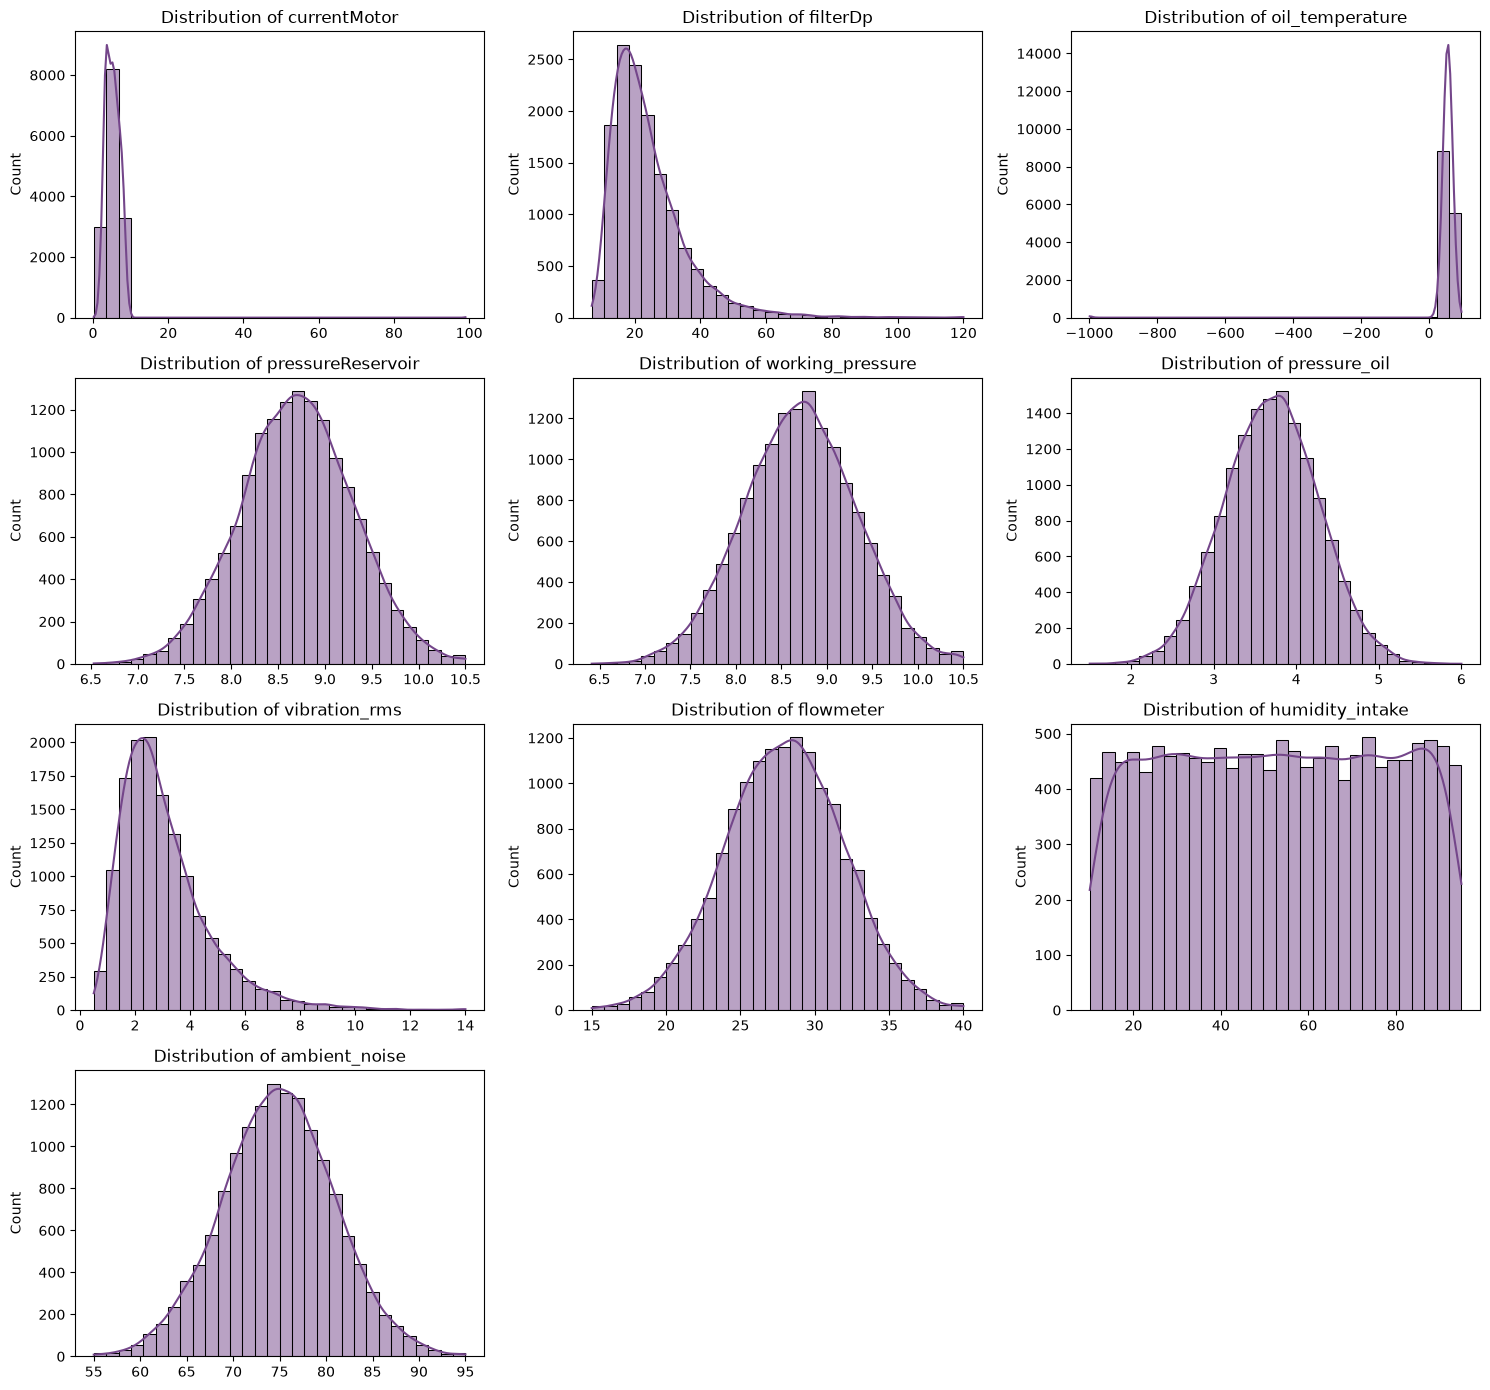

In [9]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 14))
axes = axes.flatten()

for i, attr in enumerate(selected_attributes):
    sns.histplot(readings[attr].dropna(), ax=axes[i], bins=30, kde=True, color="#74468AAE")
    axes[i].set_title(f'Distribution of {attr}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

The histograms show approximately symmetric distributions for pressure measurements, flowmeter and ambient noise. **filterDp** and **vibration_rms** are right-skewed, while humidity is broadly distributed. Four motor-current values of 99 stretch the horizontal axis, and 38 oil-temperature values of -999 dominate the temperature range. These require investigation, but a large sensor value alone is not proof of an error: it may describe a real equipment **`failure`**.

**count** excludes missing observations. Compare it with the 14,476 total rows to identify incomplete attributes. The statistics above describe raw data and may therefore be affected by duplicates and suspicious values.

Standard deviation measures spread in the original measurement units, while variance is its square. Each sensor is analysed separately; their different physical scales should not be compared as if they shared one unit.

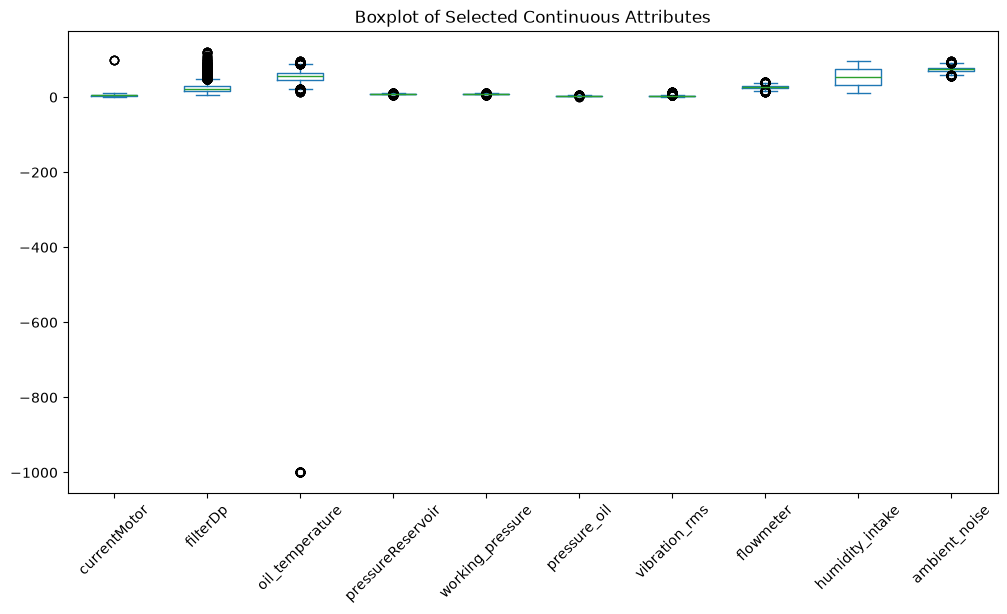

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
readings[selected_attributes].plot.box(ax=ax, rot=45)
plt.title("Boxplot of Selected Continuous Attributes")
plt.show()

This combined boxplot uses the same axis for sensors with different scales, and the temperature value -999 makes most boxes hard to read. We retain it as the original overview and add individual plots below. Boxplot outliers are statistical flags, not confirmed corrupted data or records that should automatically be removed.

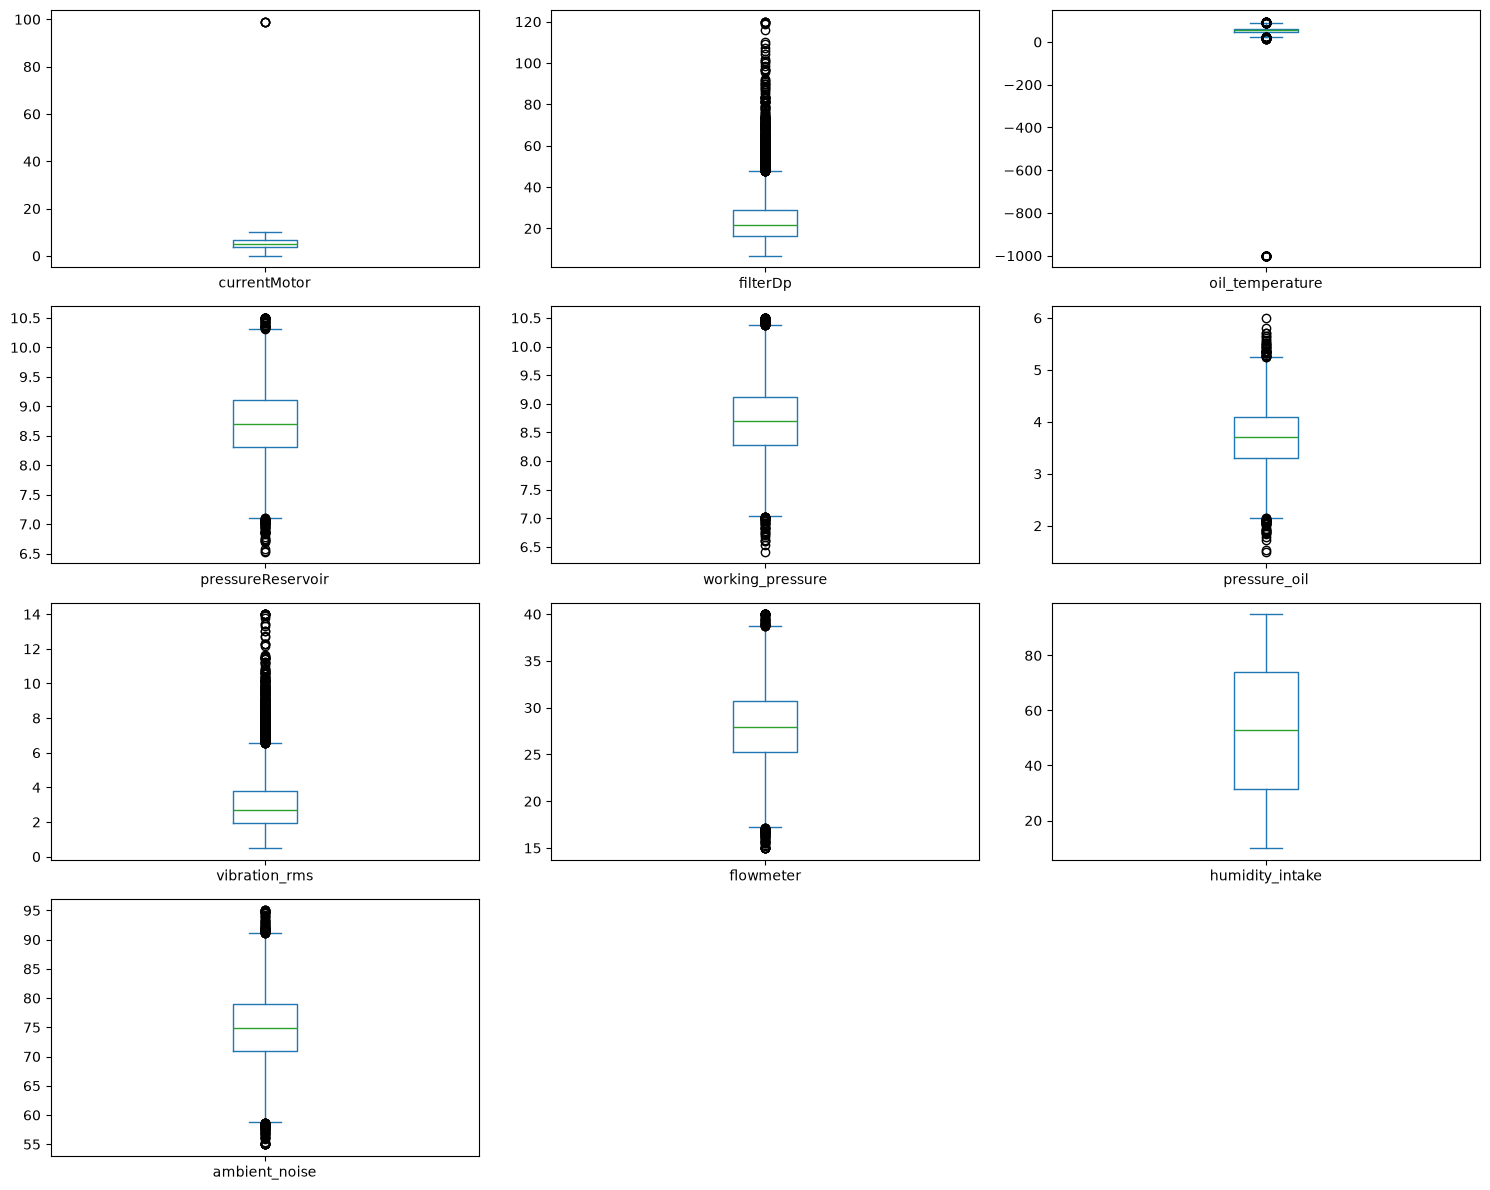

In [11]:
readings[selected_attributes].plot(
    kind='box', subplots=True, layout=(4, 3),
    sharex=False, sharey=False, figsize=(15, 12)
)
plt.tight_layout()
plt.show()


The separate boxplots make each sensor easier to inspect. Next, we look more closely at the main motor-current and temperature distributions. We exclude 99 and -999 from these two additional plots only; the original values remain in **readings**.

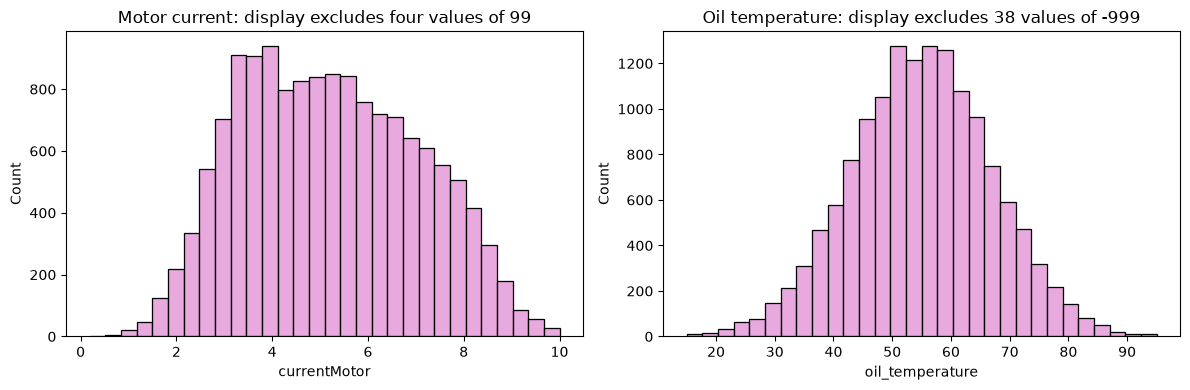

In [12]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(readings.loc[readings.currentMotor.ne(99), 'currentMotor'], bins=30, ax=axes[0], color="#df8cd496")
axes[0].set_title('Motor current: display excludes four values of 99')
sns.histplot(readings.loc[readings.oil_temperature.ne(-999), 'oil_temperature'], bins=30, ax=axes[1], color="#df8cd496")
axes[1].set_title('Oil temperature: display excludes 38 values of -999')
plt.tight_layout()
plt.show()

In [13]:
range_summary = pd.DataFrame({
    'observed_min': readings[selected_attributes].min(),
    'observed_max': readings[selected_attributes].max(),
    'missing_count': readings[selected_attributes].isna().sum(),
    'missing_percent': readings[selected_attributes].isna().mean() * 100
})
display(range_summary)
print('Humidity outside [0, 100]:',
      (readings.humidity_intake.notna() & ~readings.humidity_intake.between(0, 100)).sum())
print('Oil temperature equal to -999:', readings.oil_temperature.eq(-999).sum())
print('Motor current equal to 99:', readings.currentMotor.eq(99).sum())

,observed_min,observed_max,missing_count,missing_percent
currentMotor,0.18823,99.00000,0,0.000000
filterDp,6.93236,120.00000,540,3.730312
oil_temperature,-999.00000,95.00000,0,0.000000
pressureReservoir,6.53088,10.50000,0,0.000000
working_pressure,6.41477,10.50000,0,0.000000
pressure_oil,1.50000,6.00000,0,0.000000
vibration_rms,0.50000,14.00000,582,4.020448
flowmeter,15.00000,40.00000,0,0.000000
humidity_intake,10.00287,94.99995,733,5.063553
ambient_noise,55.00000,95.00000,0,0.000000


Humidity outside [0, 100]: 0
Oil temperature equal to -999: 38
Motor current equal to 99: 4


We summarize our interpretation for each of the ten attributes below. Observed minima and maxima are data summaries, not manufacturer-approved limits. We use explicit physical assumptions only where the meaning is clear, and leave unknown operating ranges unverified.

In [14]:
attribute_notes = pd.DataFrame([
    ('currentMotor', 'Main cluster with four values of 99', 'Check nonnegative current; investigate 99'),
    ('filterDp', 'Right-skewed with a long upper tail', 'Operating range unknown; high values may reflect faults'),
    ('oil_temperature', 'Main cluster and 38 values of -999', 'Investigate -999 as a missing-value code'),
    ('pressureReservoir', 'Approximately symmetric', 'Operating range and pressure reference not supplied'),
    ('working_pressure', 'Approximately symmetric', 'Operating range and pressure reference not supplied'),
    ('pressure_oil', 'Approximately symmetric', 'Operating range and pressure reference not supplied'),
    ('vibration_rms', 'Right-skewed', 'RMS should be nonnegative; high values need context'),
    ('flowmeter', 'Approximately symmetric', 'Flow units and direction convention not supplied'),
    ('humidity_intake', 'Broad, roughly uniform spread', 'Use [0, 100] if this is relative humidity in percent'),
    ('ambient_noise', 'Approximately symmetric', 'Units and permissible noise range not supplied')
], columns=['attribute', 'distribution_observation', 'range_interpretation']).set_index('attribute')
display(range_summary.join(attribute_notes))

,observed_min,observed_max,missing_count,missing_percent,distribution_observation,range_interpretation
currentMotor,0.18823,99.00000,0,0.000000,Main cluster with four values of 99,Check nonnegative current; investigate 99
filterDp,6.93236,120.00000,540,3.730312,Right-skewed with a long upper tail,Operating range unknown; high values may refle...
oil_temperature,-999.00000,95.00000,0,0.000000,Main cluster and 38 values of -999,Investigate -999 as a missing-value code
pressureReservoir,6.53088,10.50000,0,0.000000,Approximately symmetric,Operating range and pressure reference not sup...
working_pressure,6.41477,10.50000,0,0.000000,Approximately symmetric,Operating range and pressure reference not sup...
pressure_oil,1.50000,6.00000,0,0.000000,Approximately symmetric,Operating range and pressure reference not sup...
vibration_rms,0.50000,14.00000,582,4.020448,Right-skewed,RMS should be nonnegative; high values need co...
flowmeter,15.00000,40.00000,0,0.000000,Approximately symmetric,Flow units and direction convention not supplied
humidity_intake,10.00287,94.99995,733,5.063553,"Broad, roughly uniform spread","Use [0, 100] if this is relative humidity in p..."
ambient_noise,55.00000,95.00000,0,0.000000,Approximately symmetric,Units and permissible noise range not supplied


The assignment does not provide manufacturer operating limits or measurement units, so the observed minima/maxima are **not validated normal operating ranges**. If humidity is expressed as a percentage, all available humidity values satisfy [0, 100]. The isolated temperature value -999 is a suspected missing-value code; its meaning must be confirmed.

### (C) Pairwise data analysis

To understand multicollinearity and underlying physical relationships between sensors, we examine the pairwise correlations and dependencies among the numerical sensor attributes

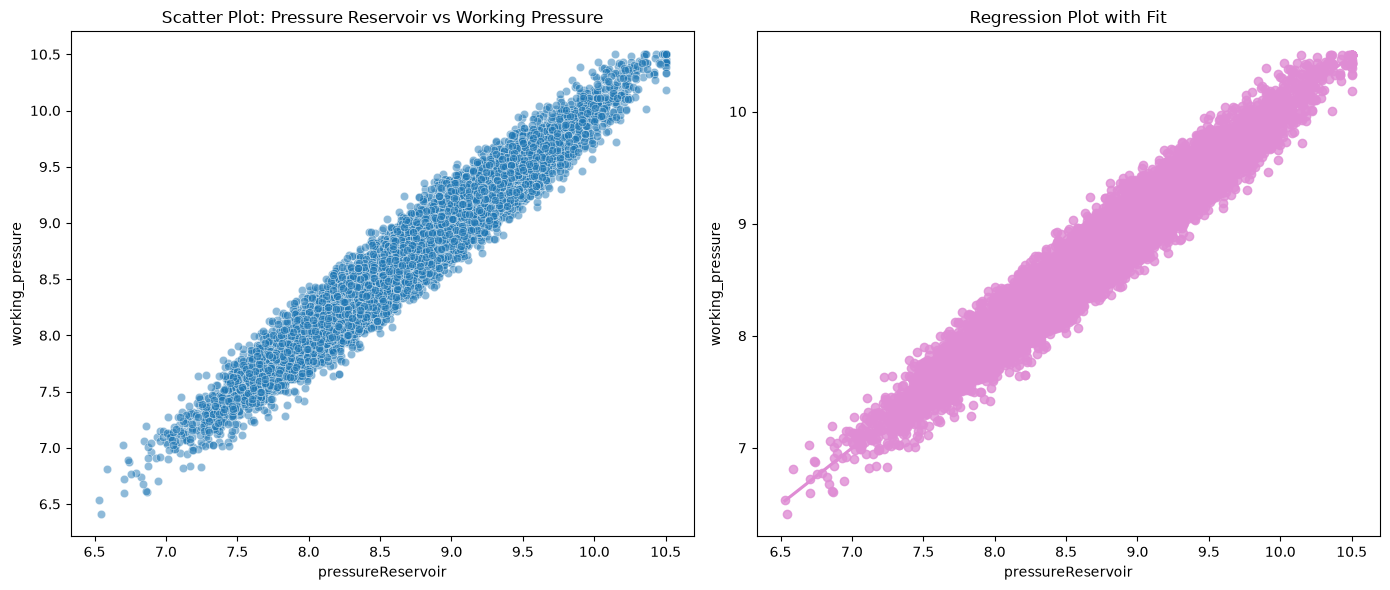

Pearson correlation: 0.970


In [15]:
fig, axes = plt.subplots(ncols=2, figsize=(14, 6))

sns.scatterplot(data=readings, x='pressureReservoir', y='working_pressure', ax=axes[0], alpha=0.5)
axes[0].set_title('Scatter Plot: Pressure Reservoir vs Working Pressure')

sns.regplot(data=readings, x='pressureReservoir', y='working_pressure', ax=axes[1], color="#df8cd496")
axes[1].set_title('Regression Plot with Fit')

plt.tight_layout()
plt.show()

print("Pearson correlation: %.3f" % readings.pressureReservoir.corr(readings.working_pressure))

We observe a strong positive correlation between working pressure and reservoir pressure (r ≈ 0.970). Higher reservoir pressure is generally associated with higher working pressure. These sensors may provide similar information for prediction; we cannot establish the cause of the relationship from this plot alone.

In [16]:
numeric_readings = readings.select_dtypes(include=[np.number])

corr_matrix = numeric_readings.corr(numeric_only=True)
display(corr_matrix)

,currentMotor,filterDp,oil_temperature,pressureReservoir,working_pressure,pressure_oil,vibration_rms,flowmeter,humidity_intake,ambient_noise,dischargeDewpoint,current_aux,failure
currentMotor,1.000000,0.013743,0.008742,0.001694,-0.002401,0.004410,-0.005853,-0.004942,0.016388,-0.014505,-0.001364,0.006232,-0.056949
filterDp,0.013743,1.000000,-0.014779,-0.003557,-0.001988,-0.001095,0.010792,0.005028,-0.006119,0.014893,0.000187,0.011702,0.125025
oil_temperature,0.008742,-0.014779,1.000000,-0.005141,-0.003027,-0.005601,0.003199,-0.000770,-0.013192,-0.009084,0.009217,0.002312,-0.017799
pressureReservoir,0.001694,-0.003557,-0.005141,1.000000,0.969899,0.847955,-0.000070,0.019236,0.017908,0.017417,0.011263,0.007693,-0.083460
working_pressure,-0.002401,-0.001988,-0.003027,0.969899,1.000000,0.822386,-0.001210,0.022202,0.020382,0.014757,0.013606,0.006925,-0.083512
pressure_oil,0.004410,-0.001095,-0.005601,0.847955,0.822386,1.000000,-0.009904,0.013437,0.011322,0.016829,0.010703,0.006302,-0.073981
vibration_rms,-0.005853,0.010792,0.003199,-0.000070,-0.001210,-0.009904,1.000000,0.008741,0.000699,0.002888,-0.004360,-0.014974,0.036131
flowmeter,-0.004942,0.005028,-0.000770,0.019236,0.022202,0.013437,0.008741,1.000000,-0.015014,0.008643,0.005374,-0.003675,-0.042243
humidity_intake,0.016388,-0.006119,-0.013192,0.017908,0.020382,0.011322,0.000699,-0.015014,1.000000,-0.009615,0.004685,0.000192,-0.016678
ambient_noise,-0.014505,0.014893,-0.009084,0.017417,0.014757,0.016829,0.002888,0.008643,-0.009615,1.000000,0.006488,0.013523,0.002734


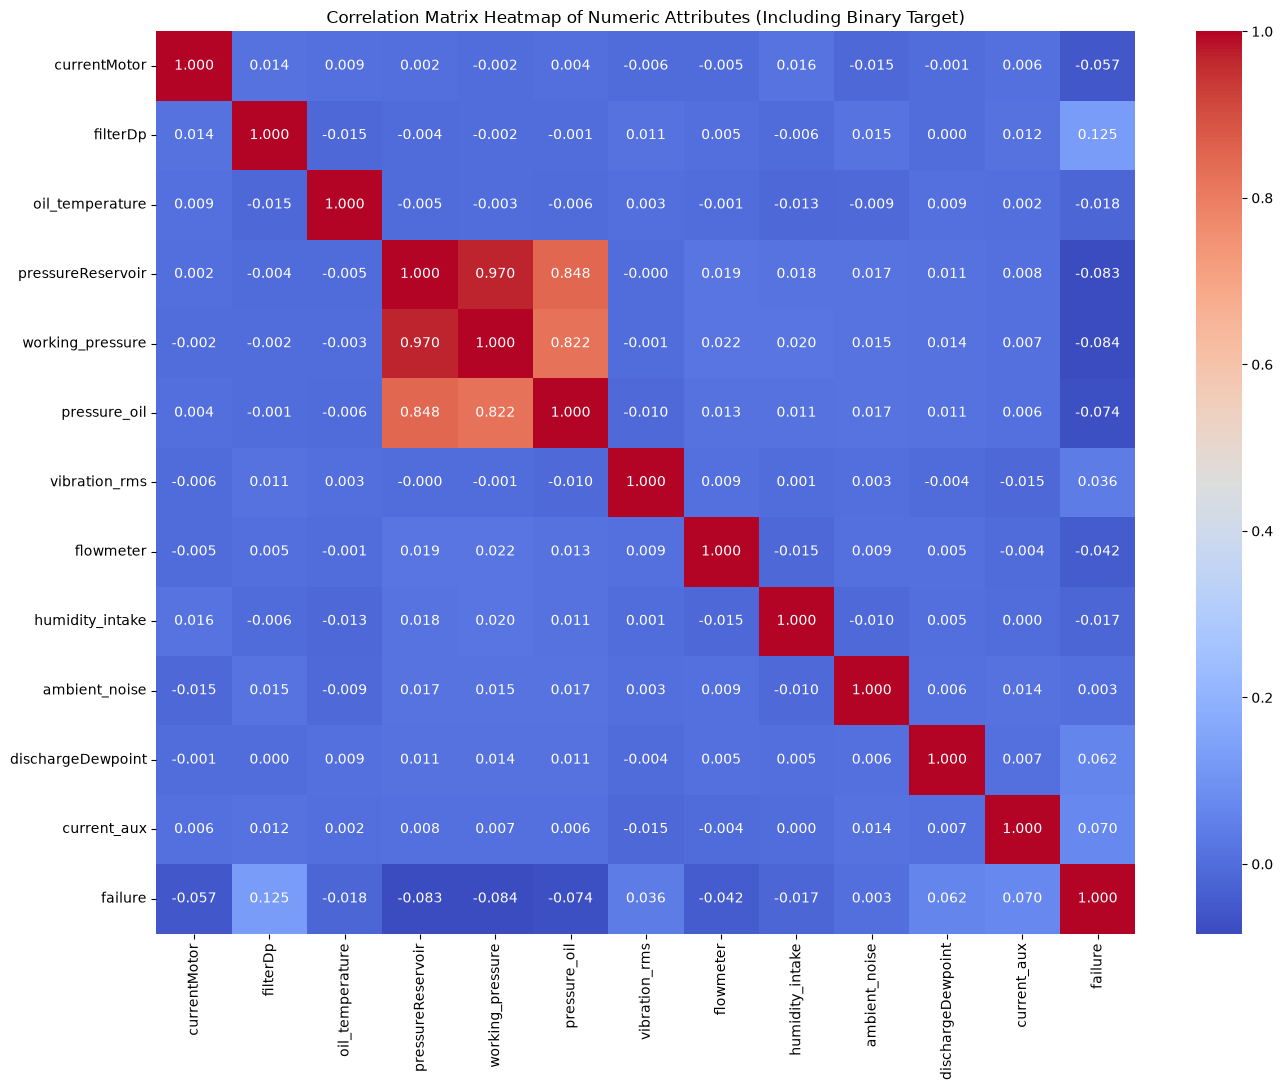

In [17]:
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr_matrix, ax=ax, annot=True, fmt=".3f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix Heatmap of Numeric Attributes (Including Binary Target)")
plt.tight_layout()
plt.show()

The strongest sensor relationships are reservoir pressure with working pressure (r ≈ 0.970), reservoir pressure with oil pressure (r ≈ 0.848), and working pressure with oil pressure (r ≈ 0.823). Most remaining pairwise linear correlations are close to zero. This does not rule out nonlinear relationships. Statistical significance is not established by a correlation heatmap alone.

The heatmap also includes binary **`failure`**; correlations with this target are examined separately in section D. Raw extremes and missing observations should be considered when interpreting the coefficients.

We compare the pressure sensors and motor current in a pairplot, using colour to distinguish failure states. We omit missing selected values only for this plot. We look for relationships between sensors and for any visible separation between the classes.

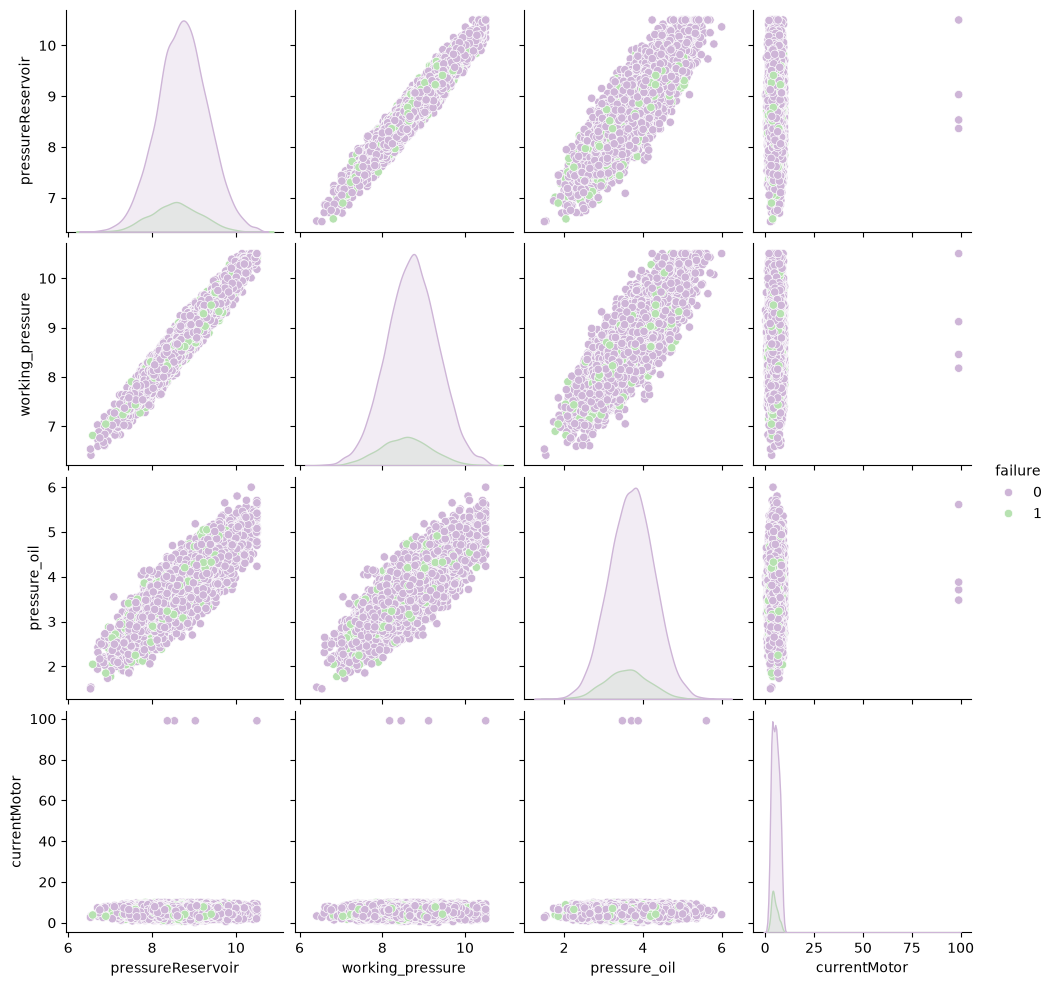

In [18]:
subset_cols = ['pressureReservoir', 'working_pressure', 'pressure_oil', 'currentMotor', 'failure']
sns.pairplot(readings[subset_cols].dropna(), hue="failure", palette= "PRGn")
plt.show()

We observe strong positive relationships between the three pressure measurements, especially between reservoir pressure and working pressure. Failure and non-failure observations overlap, so we do not see a clear separation between the groups. A few motor-current values around 99 stretch the axes and make the main cluster harder to inspect. We flag these values for further investigation.

### (D) Relationships between the target and potential predictors

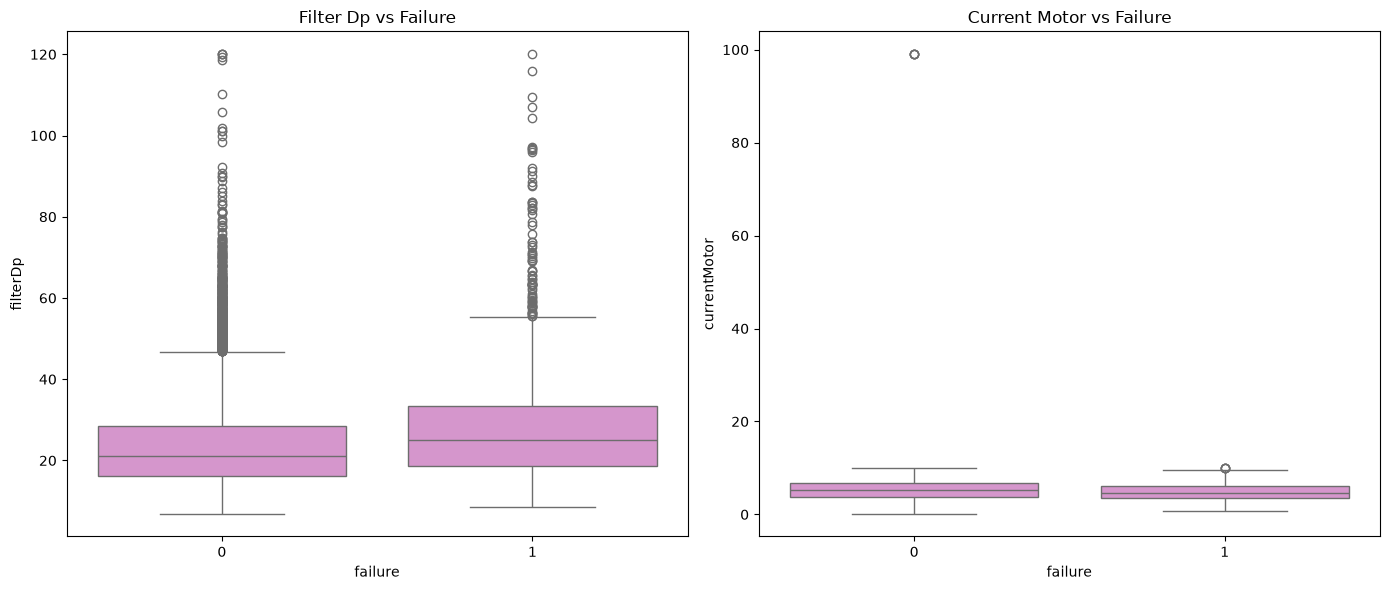

In [19]:
fig, axes = plt.subplots(ncols=2, figsize=(14, 6))

sns.boxplot(x='failure', y='filterDp', data=readings, ax=axes[0], color="#df8cd496")
axes[0].set_title('Filter Dp vs Failure')

sns.boxplot(x='failure', y='currentMotor', data=readings, ax=axes[1], color="#df8cd496")
axes[1].set_title('Current Motor vs Failure')

plt.tight_layout()
plt.show()

In [20]:
numeric_cols = readings.select_dtypes(include=[np.number]).columns.drop('failure')
target_deps = readings.groupby('failure')[numeric_cols].mean().T
display(target_deps)

target_counts = readings.failure.value_counts().sort_index()
display(pd.DataFrame({'count': target_counts, 'percent': target_counts / len(readings) * 100}))
display(readings.groupby('failure')[selected_attributes].agg(['count', 'median', 'std']).T)
display(readings.groupby('failure')[['filterDp', 'vibration_rms', 'humidity_intake']]
        .agg(lambda values: values.isna().mean() * 100)
        .rename_axis('failure'))

failure,0,1
currentMotor,5.280448,4.859295
filterDp,23.657225,28.389791
oil_temperature,52.581055,49.563499
pressureReservoir,8.721466,8.567801
working_pressure,8.722270,8.563555
pressure_oil,3.716032,3.587246
vibration_rms,3.064658,3.263348
flowmeter,28.009029,27.495172
humidity_intake,52.893523,51.635099
ambient_noise,74.889775,74.940668


,count,percent
failure,,
0,12728,87.924841
1,1748,12.075159


failure                              0            1
currentMotor      count   12728.000000  1748.000000
                  median      5.187405     4.585410
                  std         2.488655     1.684709
filterDp          count   12490.000000  1446.000000
                  median     21.046710    24.954670
                  std        11.015415    14.705324
oil_temperature   count   12728.000000  1748.000000
                  median     55.075410    54.546510
                  std        51.601345    76.685913
pressureReservoir count   12728.000000  1748.000000
                  median      8.721815     8.569635
                  std         0.599016     0.589510
working_pressure  count   12728.000000  1748.000000
                  median      8.727105     8.565760
                  std         0.618135     0.609807
pressure_oil      count   12728.000000  1748.000000
                  median      3.721490     3.589970
                  std         0.567291     0.554027
vibration_rms     count   12481.000000  1413.000000
                  median      2.685330     2.917250
                  std         1.658781     1.682031
flowmeter         count   12728.000000  1748.000000
                  median     28.039130    27.622510
                  std         3.948211     4.047586
humidity_intake   count   12095.000000  1648.000000
                  median     53.009870    51.086705
                  std        24.485059    24.699987
ambient_noise     count   12728.000000  1748.000000
                  median     74.924620    74.859280
                  std         6.057094     6.135350

,filterDp,vibration_rms,humidity_intake
failure,,,
0,1.869893,1.940603,4.973287
1,17.276888,19.164760,5.720824


We also summarize the numerical associations with the target and show the class counts. Pearson correlation with a 0/1 target describes a linear association with class membership; it does not measure the performance of a prediction model.

,Pearson_correlation_with_failure
filterDp,0.125025
working_pressure,-0.083512
pressureReservoir,-0.083460
pressure_oil,-0.073981
current_aux,0.070110
dischargeDewpoint,0.061924
currentMotor,-0.056949
flowmeter,-0.042243
vibration_rms,0.036131
oil_temperature,-0.017799


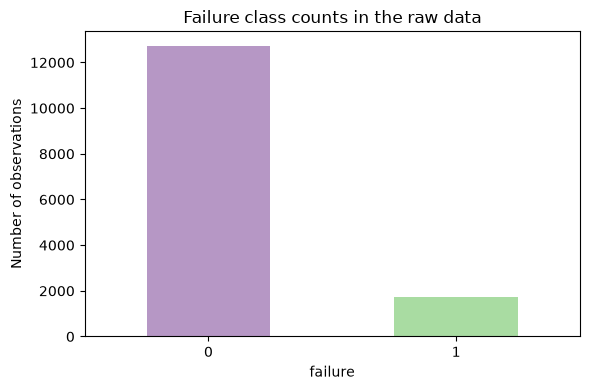

In [21]:
target_correlations = readings[numeric_cols].corrwith(readings.failure)
display(target_correlations.sort_values(key=abs, ascending=False)
        .rename('Pearson_correlation_with_failure').to_frame())
ax = target_counts.plot.bar(color=['#b697c5', '#a9dca2'], figsize=(6, 4), rot=0)
ax.set_xlabel('failure')
ax.set_ylabel('Number of observations')
ax.set_title('Failure class counts in the raw data')
plt.tight_layout()
plt.show()

The target is imbalanced: approximately **12.1%** of raw observations have **failure=1**. Mean filter differential pressure is higher in the failure group, while mean motor current is lower. The overlapping boxes show that neither attribute perfectly separates the classes. Pressure measurements, auxiliary current and discharge dewpoint may also be useful candidates; later phases must assess their predictive value.

Sensor means use available measurements only. **filterDp** and **vibration_rms** have more missing values in the failure group, which may bias comparisons. The table includes counts and medians to help assess this. These are exploratory associations; statistical verification belongs to section 1.3.

### (E) Initial thoughts on the project approach

The task is binary classification of the supplied **failure** label. Sensor readings form the observation table. Unit and explicitly linked gateway metadata may add context, so records from multiple files should be combined after normalizing IDs and checking join cardinality in section 1.2.

The pressure sensors are strongly related; compare their usefulness during feature selection rather than assuming all are independent. Filter differential pressure and motor current show differences between target groups, but their distributions overlap. Plausible extreme values may be signs of failure and should not automatically be deleted. Missing values, suspicious sentinels, duplicate observations, category variants and text dates need a documented handling strategy.

The supplied label identifies annotated failure states. Without a defined forecast horizon, classification of this label does not by itself demonstrate prediction of a future failure.

## 1.2 Identification of Problems, Data Integration, and Data Cleaning
### (A) Data formats, duplicates, missing values and integration

First, we want to find out which problems are present in our three files. We will examine them step by step, make the necessary changes and check what happened after each change. We keep the original tables from 1.1 so that we can compare the data before and after cleaning.

#### Prepare copies of our tables
We create separate copies for cleaning. We also select all 12 numeric sensor columns, excluding **failure**, because the target must not be treated as a sensor value.

In [22]:
units_clean = units.copy()
gateways_clean = gateways.copy()
readings_clean = readings.copy()
sensor_columns = readings.select_dtypes(include='number').columns.drop('failure').tolist()

#### Count duplicates and missing values

In [23]:
display(pd.DataFrame([
    {'file': name, 'rows': len(frame), 'exact_duplicates': frame.duplicated().sum(),
     'missing_values': frame.isna().sum().sum()}
    for name, frame in [('units', units), ('gateways', gateways), ('readings', readings)]
]))

,file,rows,exact_duplicates,missing_values
0,units,2000,0,100
1,gateways,16000,0,14000
2,readings,14476,214,1855


We found **214 complete duplicate readings**. The units table has 100 missing service-hour values, and 14,000 gateways do not have a unit ID. Readings also have missing sensor values. We now check which columns are affected and calculate percentages so that we can compare the files.

In [24]:
for name, frame in [('units', units), ('gateways', gateways), ('readings', readings)]:
    print(name)
    display(pd.DataFrame({'missing_count': frame.isna().sum(),
                          'missing_percent': frame.isna().mean()*100}))

units


,missing_count,missing_percent
classDuty,0,0.0
id_depot,0,0.0
id_unit,0,0.0
last_overhaul,0,0.0
owner_operator,0,0.0
number_serial,0,0.0
serviceHours,100,5.0
installRegion,0,0.0
model_code,0,0.0
fleetCode,0,0.0


gateways


,missing_count,missing_percent
firmwareVersion,0,0.0
Vendor,0,0.0
mac_address,0,0.0
gatewayId,0,0.0
hardwareModel,0,0.0
id_depot,0,0.0
date_install,0,0.0
Technician,0,0.0
id_unit,14000,87.5


readings


,missing_count,missing_percent
id_unit,0,0.000000
cycleTs,0,0.000000
currentMotor,0,0.000000
filterDp,540,3.730312
oil_temperature,0,0.000000
pressureReservoir,0,0.000000
working_pressure,0,0.000000
pressure_oil,0,0.000000
vibration_rms,582,4.020448
flowmeter,0,0.000000


The gateway unit ID is missing in **87.5%** of records. We cannot assign these devices to a particular unit without more information. In readings, the missing values are in **filterDp**, **vibration_rms** and **humidity_intake**. We keep these observations for now and examine missingness by failure state later.

#### Make unit IDs consistent
We cannot directly join `U01301` in readings to integer `1301` in units. We therefore remove the U prefix and convert IDs to integers. We use `Int64`, which allows missing values. `errors='coerce'` marks values that cannot be converted as missing, and our check stops execution if a nonmissing ID fails conversion.

In [25]:
def normalize_unit_id(values):
    text = values.astype('string').str.strip().str.replace(r'^U', '', regex=True)
    numbers = pd.to_numeric(text, errors='coerce')
    return numbers.where(numbers.mod(1).eq(0)).astype('Int64')

conversion_checks = []
for name, frame in [('units', units_clean), ('gateways', gateways_clean), ('readings', readings_clean)]:
    original_id = frame.id_unit.copy()
    frame['id_unit'] = normalize_unit_id(original_id)
    failed = int((original_id.notna() & frame.id_unit.isna()).sum())
    conversion_checks.append({'file': name, 'attribute': 'id_unit', 'failed_conversions': failed})
    assert failed == 0, f'Inspect unparseable IDs in {name}.'


display(pd.DataFrame(conversion_checks))

,file,attribute,failed_conversions
0,units,id_unit,0
1,gateways,id_unit,0
2,readings,id_unit,0


All nonmissing IDs were converted successfully. Originally missing gateway IDs remain missing.

#### Convert text dates to datetime values
We observed four date formats. We try each format explicitly and fill only dates that have not yet been parsed. The slash format with a time is interpreted as month/day/year; the text-month format uses English month abbreviations. We check conversions for all three date columns.

In [26]:
def normalize_date(values):
    result = pd.Series(pd.NaT, index=values.index, dtype='datetime64[ns]')
    for date_format in ['%Y-%m-%d', '%Y/%m/%d', '%m/%d/%Y, %H:%M:%S', '%d %b %Y']:
        result = result.fillna(pd.to_datetime(values, format=date_format, errors='coerce'))
    return result

for name, frame, attribute in [('units', units_clean, 'last_overhaul'),
                                ('gateways', gateways_clean, 'date_install'),
                                ('readings', readings_clean, 'cycleTs')]:
    original_dates = frame[attribute].copy()
    frame[attribute] = normalize_date(original_dates)
    failed = int((original_dates.notna() & frame[attribute].isna()).sum())
    conversion_checks.append({'file': name, 'attribute': attribute, 'failed_conversions': failed})
    assert failed == 0, f'Inspect unparseable dates in {name}.'
display(pd.DataFrame(conversion_checks))

,file,attribute,failed_conversions
0,units,id_unit,0
1,gateways,id_unit,0
2,readings,id_unit,0
3,units,last_overhaul,0
4,gateways,date_install,0
5,readings,cycleTs,0


There are zero failed date conversions for the observed formats. We can now compare dates chronologically instead of comparing text strings.

#### Remove extra spaces and normalize duty-label case
We remove spaces at the beginning and end of text values. We also convert **classDuty** to lowercase so that case differences do not create separate categories. We print the remaining labels to see whether formatting alone resolves the inconsistency.

In [27]:
for frame in [units_clean, gateways_clean]:
    for attribute in frame.select_dtypes(include=['object', 'string']).columns:
        frame[attribute] = frame[attribute].astype('string').str.strip()
units_clean['classDuty'] = units_clean.classDuty.str.lower()
print('Duty labels after removing whitespace and normalizing case:')
display(units_clean.classDuty.value_counts().rename('count').to_frame())

Duty labels after removing whitespace and normalizing case:


,count
classDuty,
l,288
light,257
1,252
n,181
med,180
h,176
2,172
3,170
heavy,165


We reduced **classDuty** from 20 written variants to 10 labels. Some labels may still mean the same thing, for example **l** and **light**. However, we do not know for certain what codes **1**, **2** and **3** mean or whether **med** and **normal** are equivalent. We therefore keep them separate.

#### Check duplicates again after normalization
Two records that looked different as text could become identical after date or ID conversion. We count complete duplicates again before removing them.

In [28]:
duplicate_report = []
for name, frame in [('units', units_clean), ('gateways', gateways_clean), ('readings', readings_clean)]:
    duplicate_report.append({'file': name, 'duplicates_after_normalization': frame.duplicated().sum()})
display(pd.DataFrame(duplicate_report))

,file,duplicates_after_normalization
0,units,0
1,gateways,0
2,readings,214


The count is still **214 duplicate readings**, with none in units or gateways. We remove repeated full rows so that the same observation is not counted twice. We also verify that unit and gateway keys are unique and that **`failure`** contains only 0 or 1.

In [29]:
units_clean = units_clean.drop_duplicates().copy()
gateways_clean = gateways_clean.drop_duplicates().copy()
readings_clean = readings_clean.drop_duplicates().copy()

assert units_clean.id_unit.notna().all() and units_clean.id_unit.is_unique
assert gateways_clean.gatewayId.is_unique
assert readings_clean.failure.isin([0, 1]).all(), 'Missing/invalid labels require investigation.'

#### Examine repeated unit/timestamp combinations
Sharing a unit and timestamp is not enough to prove that two rows are duplicates: their sensor values may differ. We identify these groups and count how many contain both target labels. We retain them for review instead of selecting an arbitrary row.

In [30]:
same_key = readings_clean.duplicated(['id_unit', 'cycleTs'], keep=False)
key_groups = readings_clean.groupby(['id_unit', 'cycleTs']).agg(
    record_count=('failure', 'size'), different_labels=('failure', 'nunique'))
print('Rows sharing unit/timestamp:', int(same_key.sum()))
print('Groups with conflicting failure labels:', int(key_groups.different_labels.gt(1).sum()))
display(readings_clean.loc[same_key].sort_values(['id_unit', 'cycleTs']).head(8))

Rows sharing unit/timestamp: 154
Groups with conflicting failure labels: 18


,id_unit,cycleTs,currentMotor,filterDp,oil_temperature,pressureReservoir,working_pressure,pressure_oil,vibration_rms,flowmeter,humidity_intake,ambient_noise,dischargeDewpoint,current_aux,failure
8712,51,2023-04-29,5.55791,18.01409,47.20199,9.01914,9.01107,3.85252,3.18686,31.25627,80.33131,70.43820,15.29876,3.39475,0
11470,51,2023-04-29,4.64880,43.06946,39.49862,8.07449,7.89857,2.79783,2.02337,26.23582,39.28276,77.44551,7.25587,3.13769,0
8401,62,2023-07-22,3.58650,21.66143,79.61318,8.32982,8.17251,3.78285,14.00000,30.28015,59.97629,70.19036,6.61364,3.37548,1
9081,62,2023-07-22,3.58129,23.95120,42.96398,8.84533,8.86764,3.79816,3.78231,35.42878,86.63215,79.41503,1.92356,2.74302,1
4040,85,2023-03-05,5.64441,13.51271,59.39850,7.47553,7.32705,2.73071,1.30482,27.36731,79.00209,72.44267,5.79814,2.62825,0
9994,85,2023-03-05,4.28315,15.25658,49.02127,8.94356,8.76123,3.96814,2.68167,33.14685,40.87331,77.27602,8.31847,1.11402,0
281,94,2023-08-28,3.87107,NaN,69.69430,9.04803,9.12048,4.27502,2.60398,26.21416,NaN,78.03069,11.25599,3.60442,1
8326,94,2023-08-28,2.92182,31.87232,46.87471,8.01662,7.92312,3.27019,1.68125,31.47566,32.96999,68.00256,8.99351,3.00444,0


We inspect a group that actually contains different target labels, rather than relying only on the count. We compare all its sensor values and remember that a day-only timestamp cannot distinguish separate events within that day.

In [31]:
different_label_keys = key_groups.loc[key_groups.different_labels.gt(1)].reset_index()
if not different_label_keys.empty:
    example_key = different_label_keys.iloc[0]
    example_rows = readings_clean.loc[
        readings_clean.id_unit.eq(example_key.id_unit)
        & readings_clean.cycleTs.eq(example_key.cycleTs)
    ]
    display(example_rows)
else:
    print('No repeated unit/timestamp groups contain different failure labels.')

,id_unit,cycleTs,currentMotor,filterDp,oil_temperature,pressureReservoir,working_pressure,pressure_oil,vibration_rms,flowmeter,humidity_intake,ambient_noise,dischargeDewpoint,current_aux,failure
281,94,2023-08-28,3.87107,NaN,69.69430,9.04803,9.12048,4.27502,2.60398,26.21416,NaN,78.03069,11.25599,3.60442,1
8326,94,2023-08-28,2.92182,31.87232,46.87471,8.01662,7.92312,3.27019,1.68125,31.47566,32.96999,68.00256,8.99351,3.00444,0


We found **154** rows with repeated unit/timestamp keys and **18** groups containing different failure labels. Some timestamps contain only a date, so different events during the same day may have the same recorded time. We cannot tell from these files alone whether these are annotation errors or separate measurements. We keep them and document this uncertainty.



#### Integrate the three files
We use **id_unit** as the link. First we select gateways with an explicit unit ID and check that this key is unique. We use a left join from readings, because the sensor observations are our main table. `validate='many_to_one'` checks that each observation matches at most one metadata row. The indicators tell us which observations did not find a match.

In [32]:
linked_gateways = gateways_clean.loc[gateways_clean.id_unit.notna()].copy()
assert linked_gateways.id_unit.is_unique, 'Resolve multiple gateways per unit before joining.'
integrated = readings_clean.merge(
    units_clean, on='id_unit', how='left', validate='many_to_one', indicator='unit_match')
integrated = integrated.merge(
    linked_gateways, on='id_unit', how='left', validate='many_to_one',
    suffixes=('_unit', '_gateway'), indicator='gateway_match')
assert len(integrated) == len(readings_clean), 'Integration must not multiply sensor rows.'

We have joined the tables. Now we check the match counts and confirm that joining has not multiplied the readings. We also look at a few unmatched IDs.

In [33]:
display(integrated[['unit_match', 'gateway_match']].apply(lambda column: column.value_counts()))
print('Original readings:', len(readings))
print('After duplicate removal and integration:', len(integrated))
print('Gateways without an explicit unit link:', gateways_clean.id_unit.isna().sum())
display(integrated.loc[integrated.unit_match.eq('left_only'), ['id_unit', 'cycleTs', 'failure']].head())

,unit_match,gateway_match
both,14127,14127
left_only,135,135
right_only,0,0


Original readings: 14476
After duplicate removal and integration: 14262
Gateways without an explicit unit link: 14000


,id_unit,cycleTs,failure
64,90029,2023-01-24 00:00:00,0
193,90024,2023-03-02 00:00:00,0
211,90272,2023-03-03 00:00:00,0
319,90055,2023-02-11 20:00:00,0
491,90309,2023-07-06 00:00:00,0


After removing duplicates, we have **14,262** observations. Integration preserves this count: **14,127** observations match metadata, while **135** do not. We retain those 135 rows with missing metadata. We do not join through depot, because a depot contains multiple units and gateways and would not identify the correct device.

### (B) Correctness and logical consistency
#### Check suspicious values and relationships
We count suspected temperature sentinels, motor-current extremes, invalid humidity percentages, negative nonnegative quantities and infinite values. We also compare depots and metadata dates. These are diagnostic checks: a flagged row needs interpretation before we decide to change it.

In [34]:
checks = {
    'oil_temperature equals suspected sentinel -999': integrated.oil_temperature.eq(-999),
    'currentMotor equals suspicious extreme 99': integrated.currentMotor.eq(99),
    'humidity outside [0, 100]': integrated.humidity_intake.notna() & ~integrated.humidity_intake.between(0, 100),
    'negative motor current': integrated.currentMotor.lt(0),
    'negative RMS vibration': integrated.vibration_rms.lt(0),
    'negative service hours': integrated.serviceHours.lt(0),
    'any infinite sensor value': pd.Series(np.isinf(integrated[sensor_columns].to_numpy()).any(axis=1), index=integrated.index),
    'unit/gateway depot mismatch': integrated.id_depot_unit.notna() & integrated.id_depot_gateway.notna()
                                   & integrated.id_depot_unit.ne(integrated.id_depot_gateway),
    'reading earlier than last overhaul': integrated.cycleTs.lt(integrated.last_overhaul),
    'reading earlier than gateway installation': integrated.cycleTs.lt(integrated.date_install)
}
display(pd.DataFrame({'flagged_rows': {name: int(mask.sum()) for name, mask in checks.items()}}))
display(integrated.loc[checks['reading earlier than last overhaul'],
                       ['id_unit', 'cycleTs', 'last_overhaul', 'failure']].head())

,flagged_rows
oil_temperature equals suspected sentinel -999,38
currentMotor equals suspicious extreme 99,4
"humidity outside [0, 100]",0
negative motor current,0
negative RMS vibration,0
negative service hours,0
any infinite sensor value,0
unit/gateway depot mismatch,0
reading earlier than last overhaul,2044
reading earlier than gateway installation,2011


,id_unit,cycleTs,last_overhaul,failure
20,1628,2023-03-21,2024-02-29,0
22,1957,2023-12-05,2024-08-11,0
33,373,2023-06-06,2024-10-07,0
35,41,2023-12-08,2024-09-24,0
37,1075,2023-10-17,2024-12-09,0


We inspect examples of the suspected sensor values and the installation-date warning. These examples make the issue visible and help us decide whether a value can be corrected or needs additional information.

In [35]:
display(integrated.loc[
    checks['oil_temperature equals suspected sentinel -999']
    | checks['currentMotor equals suspicious extreme 99'],
    ['id_unit', 'cycleTs', 'oil_temperature', 'currentMotor', 'failure']
].head(10))
display(integrated.loc[checks['reading earlier than gateway installation'],
                       ['id_unit', 'cycleTs', 'date_install', 'failure']].head())

,id_unit,cycleTs,oil_temperature,currentMotor,failure
278,1058,2023-06-12 14:00:00,-999.00000,6.01879,0
891,1303,2023-05-01 00:00:00,73.62785,99.00000,0
1082,1003,2023-08-01 00:00:00,-999.00000,2.90119,0
1391,915,2023-03-20 16:22:00,-999.00000,5.58933,0
1642,1864,2023-06-21 00:00:00,-999.00000,5.67105,1
1791,949,2023-12-22 00:00:00,-999.00000,2.98431,0
1805,417,2023-09-26 15:46:00,-999.00000,5.48161,0
1847,266,2023-10-16 00:00:00,-999.00000,8.19119,0
2209,481,2023-04-17 00:00:00,-999.00000,4.91488,0
2380,182,2023-11-13 00:00:00,53.20483,99.00000,0


,id_unit,cycleTs,date_install,failure
6,1833,2023-07-02 00:00:00,2023-07-23,0
7,1347,2023-04-26 00:00:00,2024-09-01,0
9,204,2023-06-07 16:15:00,2023-10-17,0
25,901,2023-03-14 00:00:00,2023-05-23,0
27,1078,2023-03-23 01:09:00,2023-10-24,0


We found **38 temperatures equal to -999** and **four motor-current readings equal to 99**. The other range checks and the depot comparison do not flag any rows. These checks do not validate all possible operating limits, because manufacturer ranges and measurement units are not supplied.

There are **2,044** observations before the recorded last overhaul and **2,011** before gateway installation. The metadata may describe a later snapshot, so we do not delete those readings. We would need to establish what metadata were available at measurement time before using them as predictors.

#### Handle the suspected temperature sentinel
The isolated -999 value is far from the rest of the temperatures. We provisionally interpret it as a missing-measurement code and replace it with NaN. We keep a Boolean flag so that this decision can be inspected or reversed. 

We retain current 99: it could be an error or a real extreme during a failure. We also include handling for infinite values and humidity outside [0, 100], although our checks found none in this dataset.

In [36]:
eda_clean = integrated.copy()
eda_clean['oil_temperature_sentinel_flag'] = eda_clean.oil_temperature.eq(-999)
eda_clean.loc[eda_clean.oil_temperature_sentinel_flag, 'oil_temperature'] = np.nan
eda_clean[sensor_columns] = eda_clean[sensor_columns].replace([np.inf, -np.inf], np.nan)
eda_clean.loc[checks['humidity outside [0, 100]'], 'humidity_intake'] = np.nan

#### Check missingness after initial cleaning
We compare missing counts before and after cleaning. A smaller count in some columns comes from duplicate removal, not from filling the missing values. Temperature now has 38 missing values because of our sentinel decision.

We also calculate missing-value percentages separately for `failure=0` and `failure=1`, and compare the temperature mean before and after the replacement.

In [37]:
display(pd.DataFrame({
    'raw_missing_count': readings[sensor_columns].isna().sum(),
    'clean_missing_count': eda_clean[sensor_columns].isna().sum(),
    'clean_missing_percent': eda_clean[sensor_columns].isna().mean()*100
}))
display(eda_clean.groupby('failure')[['filterDp', 'vibration_rms', 'humidity_intake', 'oil_temperature']]
        .agg(lambda column: column.isna().mean()*100))
print('Temperature mean before sentinel handling:', integrated.oil_temperature.mean())
print('Temperature mean after sentinel handling:', eda_clean.oil_temperature.mean())

,raw_missing_count,clean_missing_count,clean_missing_percent
currentMotor,0,0,0.000000
filterDp,540,525,3.681111
oil_temperature,0,38,0.266442
pressureReservoir,0,0,0.000000
working_pressure,0,0,0.000000
pressure_oil,0,0,0.000000
vibration_rms,582,577,4.045716
flowmeter,0,0,0.000000
humidity_intake,733,725,5.083439
ambient_noise,0,0,0.000000


,filterDp,vibration_rms,humidity_intake,oil_temperature
failure,,,,
0,1.833108,1.952658,4.981270,0.231131
1,17.201166,19.358601,5.830904,0.524781


Temperature mean before sentinel handling: 52.16405091221427
Temperature mean after sentinel handling: 54.97227883225534


The temperature mean changes from approximately **52.16 to 54.97** after sentinel handling on the deduplicated data. This shows why a value such as -999 distorts the summary.

Missing **filterDp** values occur in about **1.8%** of nonfailure observations and **17.2%** of failure observations. For vibration, the corresponding percentages are approximately **2.0% and 19.4%**. Missingness therefore differs between the groups and may affect comparisons based only on available measurements.


We now compare two practical ways of handling these missing sensor values.

#### Compare deletion with statistical imputation
We remove an observation if any sensor is missing. We then try `SimpleImputer` with both mean and median strategies, as a statistical-imputation experiment. We compare the two strategies because skewed distributions and extreme values can pull the mean away from typical values.

We fit each imputer without using **`failure`**. These are Phase 1 descriptive experiments on separate copies, not data prepared for ML evaluation. In Phase 2, we must split the original observations first and fit any imputer on training data only. We do not fill unknown unit IDs, metadata or target labels.

In [ ]:
from sklearn.impute import SimpleImputer

complete_cases = eda_clean.dropna(subset=sensor_columns).copy()
mean_imputed = eda_clean.copy()
median_imputed = eda_clean.copy()

mean_imputer = SimpleImputer(strategy='mean')
median_imputer = SimpleImputer(strategy='median')
mean_imputed[sensor_columns] = mean_imputer.fit_transform(eda_clean[sensor_columns])
median_imputed[sensor_columns] = median_imputer.fit_transform(eda_clean[sensor_columns])

missing_sensor_columns = eda_clean[sensor_columns].columns[eda_clean[sensor_columns].isna().any()]
for attribute in missing_sensor_columns:
    median_imputed[attribute + '_was_missing'] = eda_clean[attribute].isna()

imputation_comparison = pd.DataFrame([
    {'method': name, 'rows': len(frame), 'failure_rows': int(frame.failure.sum()),
     'failure_percent': frame.failure.mean()*100,
     'missing_sensor_values': int(frame[sensor_columns].isna().sum().sum())}
    for name, frame in [('initial_cleaning', eda_clean), ('complete_cases', complete_cases),
                        ('mean_imputation', mean_imputed), ('median_imputation', median_imputed)]
])
display(imputation_comparison)
display(pd.DataFrame({'mean_fill_value': mean_imputer.statistics_,
                      'median_fill_value': median_imputer.statistics_}, index=sensor_columns)
        .loc[missing_sensor_columns])
print('Failure observations lost by complete-case deletion:',
      int(eda_clean.failure.sum() - complete_cases.failure.sum()))

,method,rows,failure_rows,failure_percent,missing_sensor_values
0,initial_cleaning,14262,1715,12.024961,1865
1,complete_cases,12520,1073,8.570288,0
2,mean_imputation,14262,1715,12.024961,0
3,median_imputation,14262,1715,12.024961,0


,mean_fill_value,median_fill_value
filterDp,24.145911,21.447790
oil_temperature,54.972279,55.047755
vibration_rms,3.079998,2.703400
humidity_intake,52.733068,52.886330


Failure observations lost by complete-case deletion: 642


Complete-case deletion removes **1,742** observations, including **642** failure observations (**37.4%** of all failures). The failure proportion falls from **12.02%** to **8.57%**. We therefore avoid deleting all incomplete observations as our default. Both imputers preserve rows, but filled values are estimates rather than recovered measurements. We now compare the affected sensors' means, medians and standard deviations and inspect the distributions.

available_values                       mean_filled             \
                            mean     median        std        mean     median   
filterDp               24.145911  21.447790  11.544389   24.145911  21.857530   
oil_temperature        54.972279  55.047755  11.982035   54.972279  55.014010   
vibration_rms           3.079998   2.703400   1.658213    3.079998   2.773915   
humidity_intake        52.733068  52.886330  24.508846   52.733068  52.733068   

                           median_filled                        
                       std          mean     median        std  
filterDp         11.329900     24.046590  21.447790  11.341286  
oil_temperature  11.966061     54.972480  55.047755  11.966061  
vibration_rms     1.624321      3.064762   2.703400   1.626015  
humidity_intake  23.877730     52.740859  52.886330  23.877754

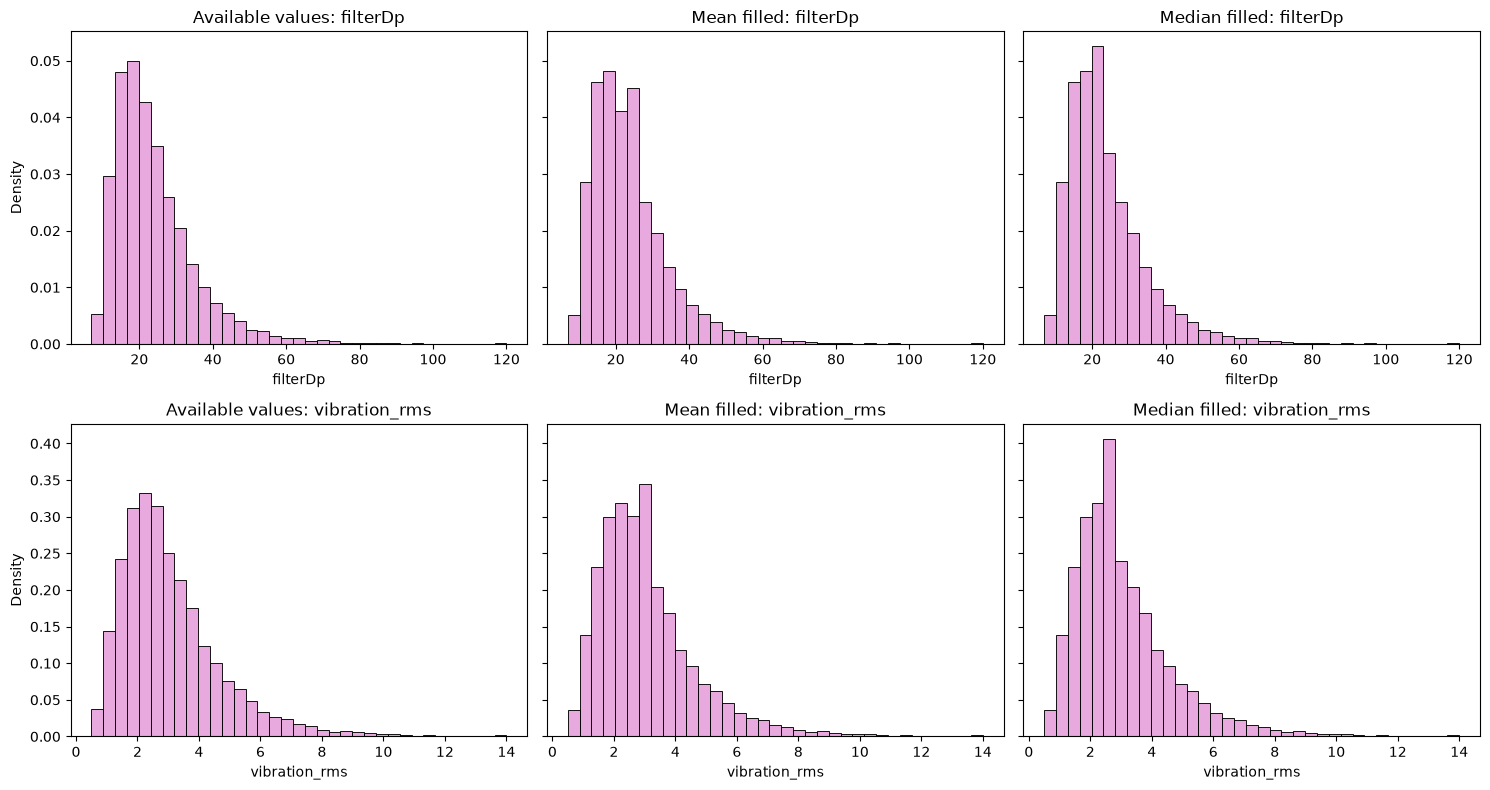

In [39]:
imputation_statistics = pd.concat({
    name: frame[missing_sensor_columns].agg(['mean', 'median', 'std']).T
    for name, frame in [('available_values', eda_clean), ('mean_filled', mean_imputed),
                        ('median_filled', median_imputed)]
}, axis=1)
display(imputation_statistics)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex='row', sharey='row')
for row, attribute in enumerate(['filterDp', 'vibration_rms']):
    # Identical bins and axes allow us to compare the shapes fairly.
    bins = np.histogram_bin_edges(eda_clean[attribute].dropna(), bins=35)
    for col, (name, frame) in enumerate([
        ('Available values', eda_clean), ('Mean filled', mean_imputed), ('Median filled', median_imputed)
    ]):
        sns.histplot(frame[attribute].dropna(), bins=bins, stat='density',
                     color='#df8cd496', ax=axes[row, col])
        axes[row, col].set_title(name + ': ' + attribute)
plt.tight_layout()
plt.show()

We observe that constant-value imputation puts additional observations at the chosen mean or median and generally reduces the measured spread. It cannot reconstruct the unknown sensor readings. Because missingness differs by failure status, global filling can also weaken real differences between the groups.

We therefore keep `eda_clean` with NaN values as the main table for describing observed measurements. We retain `median_imputed` as a practical, explicitly labelled filled alternative, with missingness flags; its median estimates are less sensitive to extreme values than mean estimates. The actual choice for prediction must be evaluated using training-fitted preprocessing. We have applied and compared missing-value treatments here without claiming that imputation restores the true values.

### (C) Outlier detection and treatment
#### Detect outliers using IQR and three standard deviations
We calculate the first and third quartiles for each sensor. Their difference is the interquartile range: **IQR = Q3 - Q1**. We flag values below **Q1 - 1.5 × IQR** or above **Q3 + 1.5 × IQR**.

We also flag values outside **mean ± 3 × standard deviation**. Comparing both counts helps us see how the choice of method changes the result. The 3-SD rule is better suited to approximately Gaussian distributions, while IQR is less affected by extreme values. Neither rule establishes that a flagged reading is wrong.

In [40]:
sensor_data = eda_clean[sensor_columns]
q1, q3 = sensor_data.quantile(.25), sensor_data.quantile(.75)
iqr = q3-q1
lower_iqr, upper_iqr = q1-1.5*iqr, q3+1.5*iqr
iqr_flags = sensor_data.lt(lower_iqr) | sensor_data.gt(upper_iqr)
mean, std = sensor_data.mean(), sensor_data.std()
sd_flags = sensor_data.lt(mean-3*std) | sensor_data.gt(mean+3*std)
display(pd.DataFrame({'IQR_lower': lower_iqr, 'IQR_upper': upper_iqr,
                      'IQR_flagged': iqr_flags.sum(), '3SD_flagged': sd_flags.sum()}))

,IQR_lower,IQR_upper,IQR_flagged,3SD_flagged
currentMotor,-0.638773,10.968428,4,4
filterDp,-2.730915,47.929045,563,235
oil_temperature,22.566430,87.390950,92,38
pressureReservoir,7.098986,10.307116,108,21
working_pressure,7.032282,10.372422,98,16
pressure_oil,2.149405,5.249085,75,32
vibration_rms,-0.845550,6.568850,564,228
flowmeter,17.216581,38.734011,101,39
humidity_intake,-32.257720,137.681400,0,0
ambient_noise,58.749569,91.083719,109,39


The methods flag different numbers of readings. For example, *IQR* flags **563** **filterDp** values, while the *3-SD rule* flags **235**. We should therefore compare the consequences of treatment instead of automatically removing everything flagged.



#### First treatment: remove rows with IQR outliers
On a separate copy, we remove any row with at least one sensor outside its IQR limits. Missing values are not marked as outliers by these comparisons.

In [41]:
iqr_removed = eda_clean.loc[~iqr_flags.any(axis=1)].copy()

print('Rows retained after IQR removal:', len(iqr_removed))

Rows retained after IQR removal: 12517


#### Second treatment: clip to percentile boundaries
We create another copy and calculate the 5th and 95th percentiles for each sensor. This keeps the rows and labels but changes sensor readings. The boundaries are calculated without separating the failure classes.

In [42]:
percentile_clipped = eda_clean.copy()
lower_clip, upper_clip = sensor_data.quantile(.05), sensor_data.quantile(.95)
percentile_clipped[sensor_columns] = sensor_data.clip(lower=lower_clip, upper=upper_clip, axis=1)
display(pd.DataFrame({'clip_5_percent': lower_clip, 'clip_95_percent': upper_clip,
                      'changed_values': (sensor_data.lt(lower_clip) | sensor_data.gt(upper_clip)).sum()}))

,clip_5_percent,clip_95_percent,changed_values
currentMotor,2.453572,8.308687,1428
filterDp,11.633450,45.728102,1374
oil_temperature,35.250010,74.584733,1424
pressureReservoir,7.709020,9.694674,1428
working_pressure,7.677813,9.725132,1428
pressure_oil,2.770539,4.629780,1428
vibration_rms,1.164096,6.259564,1370
flowmeter,21.326175,34.407369,1428
humidity_intake,14.587070,90.648820,1354
ambient_noise,64.742951,84.835247,1428


Clipping modifies roughly 10% of the available values per sensor. This includes plausible tail values, not just confirmed errors. The table above shows the chosen boundaries and the number of changes.



#### Compare the effects on observations and failures
We compare the initial cleaned data and both experimental treatments. We look at total rows, failure counts, class balance, sensor means and medians. We also check which class is more often flagged by IQR.

In [43]:
comparison = pd.DataFrame([
    {'method': name, 'rows': len(frame), 'failure_rows': int(frame.failure.sum()),
     'failure_percent': frame.failure.mean()*100,
     'filterDp_mean': frame.filterDp.mean(), 'filterDp_median': frame.filterDp.median(),
     'vibration_mean': frame.vibration_rms.mean(), 'motor_current_max': frame.currentMotor.max()}
    for name, frame in [('initial_cleaning', eda_clean), ('IQR_removal', iqr_removed),
                        ('5_95_clipping', percentile_clipped)]
])
display(comparison)
display(eda_clean.assign(IQR_flag=iqr_flags.any(axis=1)).groupby('failure').IQR_flag.agg(['sum', 'mean']))
assert len(percentile_clipped) == len(eda_clean)
assert percentile_clipped.failure.equals(eda_clean.failure)
assert not iqr_removed.duplicated().any()

,method,rows,failure_rows,failure_percent,filterDp_mean,filterDp_median,vibration_mean,motor_current_max
0,initial_cleaning,14262,1715,12.024961,24.145911,21.44779,3.079998,99.000000
1,IQR_removal,12517,1456,11.632180,22.563842,20.93700,2.861432,10.000000
2,5_95_clipping,14262,1715,12.024961,23.585066,21.44779,3.009901,8.308687


,sum,mean
failure,,
0,1486,0.118435
1,259,0.151020


IQR removal discards **1,745** observations, including **259** failure observations. This is **15.1%** of failure observations, compared with **11.8%** of nonfailure observations. The failure proportion falls from 12.02% to 11.63%.

Clipping preserves all 14,262 rows and their labels, but lowers some extreme sensor readings. We now visualize these changes to see how the distributions differ.

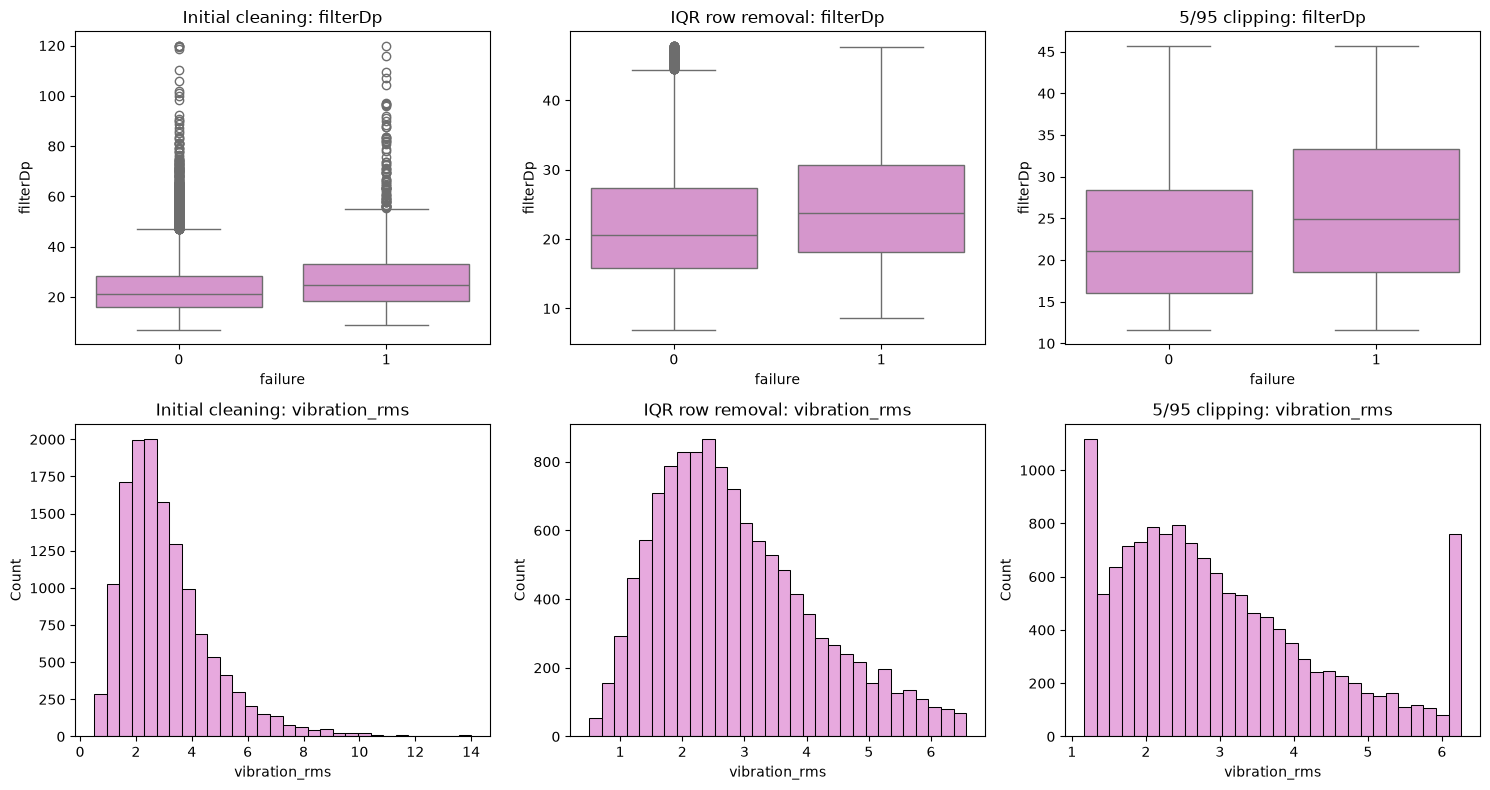

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, (name, frame) in enumerate([
    ('Initial cleaning', eda_clean), ('IQR row removal', iqr_removed), ('5/95 clipping', percentile_clipped)
]):
    sns.boxplot(data=frame, x='failure', y='filterDp', ax=axes[0, column], color="#df8cd496")
    axes[0, column].set_title(name + ': filterDp')
    sns.histplot(frame.vibration_rms.dropna(), bins=30, ax=axes[1, column], color="#df8cd496")
    axes[1, column].set_title(name + ': vibration_rms')
plt.tight_layout()
plt.show()

In the boxplots, IQR removal shortens the tails by removing rows, while clipping places extreme values at the chosen boundaries. The clipped vibration histogram has concentrations near its boundaries because several original readings are replaced by the same value. We compare numerical summaries as well, rather than relying on the plots alone.

In [45]:
display(pd.DataFrame({
    'raw_mean': readings[selected_attributes].mean(),
    'initial_clean_mean': eda_clean[selected_attributes].mean(),
    'IQR_removed_mean': iqr_removed[selected_attributes].mean(),
    'clipped_mean': percentile_clipped[selected_attributes].mean()
}))

,raw_mean,initial_clean_mean,IQR_removed_mean,clipped_mean
currentMotor,5.229593,5.230903,5.211862,5.204458
filterDp,24.148276,24.145911,22.563842,23.585066
oil_temperature,52.216680,54.972279,54.976132,54.982494
pressureReservoir,8.702911,8.702536,8.703913,8.702302
working_pressure,8.703105,8.702683,8.704318,8.702600
pressure_oil,3.700481,3.700238,3.700362,3.699918
vibration_rms,3.084864,3.079998,2.861432,3.009901
flowmeter,27.946980,27.946462,27.953652,27.947140
humidity_intake,52.742618,52.733068,52.790255,52.738387
ambient_noise,74.895920,74.898502,74.898163,74.886001


#### Our decision after comparing outlier treatments
We keep plausible extreme readings in **`eda_clean`**, because faults can produce unusual measurements. IQR removal discards 1,745 rows, including 259 failure observations, so it loses a larger fraction of failures than nonfailures. Percentile clipping preserves labels but changes possible failure signals. We retain both treated copies for comparison, rather than applying them automatically to the main table.

We have now examined both missing-value handling and outlier handling separately. This lets us identify which treatment caused each change. Future model evaluation can compare combinations, fitting all distribution-based parameters on training data only.

#### Verify our result
We check that complete duplicates are gone, all observed dates were converted, joins preserved observations, and the original sensor values and labels survived integration. We separately verify that the imputed copies contain no missing sensors and that imputation did not change observed values or target labels. These checks describe what has been corrected; they do not certify unknown operating limits.

In [ ]:
assert not readings_clean.duplicated().any()
assert len(integrated) == len(readings_clean)
assert integrated.failure.reset_index(drop=True).equals(readings_clean.failure.reset_index(drop=True))
pd.testing.assert_frame_equal(integrated[sensor_columns].reset_index(drop=True),
                              readings_clean[sensor_columns].reset_index(drop=True))
assert all(item['failed_conversions'] == 0 for item in conversion_checks)
assert pd.api.types.is_datetime64_any_dtype(readings_clean.cycleTs)
assert pd.api.types.is_datetime64_any_dtype(units_clean.last_overhaul)
assert pd.api.types.is_datetime64_any_dtype(gateways_clean.date_install)
assert not eda_clean.oil_temperature.eq(-999).any()
assert eda_clean.failure.equals(integrated.failure)
for filled in [mean_imputed, median_imputed]:
    assert filled[sensor_columns].notna().all().all()
    assert filled.failure.equals(eda_clean.failure)
    for attribute in sensor_columns:
        observed = eda_clean[attribute].notna()
        assert filled.loc[observed, attribute].equals(eda_clean.loc[observed, attribute])
assert percentile_clipped[sensor_columns].isna().equals(eda_clean[sensor_columns].isna())
assert percentile_clipped.failure.equals(eda_clean.failure)

for name, cfg in file_configs.items():
    original_file = pd.read_csv(cfg['path'], sep=cfg['sep'], encoding='utf-8', on_bad_lines='error')
    pd.testing.assert_frame_equal(data_frames[name], original_file)
print('All checks passed: formats, joins, labels, original data and treatment copies are consistent.')

All checks passed: formats, joins, labels, original data and treatment copies are consistent.


#### Summary of identified problems and our decisions
We collect the findings in one table so that we can explain each decision. Counts refer to the stage stated in the first column; they are not all counts of unique equipment.

In [47]:
problem_summary = pd.DataFrame([
    ('Raw readings: full duplicate rows', int(readings.duplicated().sum()),
     'Remove full duplicates after normalization', 'Avoid counting the same recorded observation twice'),
    ('Date conversion failures', sum(x['failed_conversions'] for x in conversion_checks if x['attribute'] != 'id_unit'),
     'Parse four explicit date formats', 'All supplied nonmissing dates were parsed'),
    ('Raw duty-label variants', units.classDuty.nunique(),
     f'Strip spaces/lowercase; {units_clean.classDuty.nunique()} labels remain', 'Code meanings still need confirmation'),
    ('Gateways without a unit ID', int(gateways_clean.id_unit.isna().sum()),
     'Keep unlinked gateway records separately', 'Do not invent an equipment assignment'),
    ('Integrated observations without unit metadata', int(integrated.unit_match.eq('left_only').sum()),
     'Retain observations with missing metadata', 'Sensor information is still available'),
    ('Repeated unit/time groups with different labels', int(key_groups.different_labels.gt(1).sum()),
     'Inspect and retain for clarification', 'Day-only times may represent separate events'),
    ('Deduplicated temperature values equal to -999', int(eda_clean.oil_temperature_sentinel_flag.sum()),
     'Replace with NaN and retain a flag', 'Provisional missing-code interpretation'),
    ('Deduplicated current values equal to 99', int(eda_clean.currentMotor.eq(99).sum()),
     'Retain and flag for review', 'Operating limits are unknown; possible real extremes'),
    ('Sensor NaNs after initial cleaning', int(eda_clean[sensor_columns].isna().sum().sum()),
     'Compare deletion, mean and median filling', 'Keep observed-data and imputed alternatives distinct'),
    ('Unit serviceHours missing in unit table', int(units_clean.serviceHours.isna().sum()),
     'Retain missing metadata', 'Do not confuse an unknown value with zero hours'),
    ('Observations before last overhaul', int(checks['reading earlier than last overhaul'].sum()),
     'Retain readings; review metadata availability', 'Later snapshots may leak future information'),
    ('Observations before gateway installation', int(checks['reading earlier than gateway installation'].sum()),
     'Retain readings; review metadata availability', 'Historical assignment cannot be confirmed'),
    ('Observations flagged by any IQR sensor limit', int(iqr_flags.any(axis=1).sum()),
     'Compare IQR deletion with 5/95 clipping', 'Main table retains plausible failure signals')
], columns=['problem_or_check', 'count', 'our_action', 'reason_or_remaining_issue'])
display(problem_summary)

,problem_or_check,count,our_action,reason_or_remaining_issue
0,Raw readings: full duplicate rows,214,Remove full duplicates after normalization,Avoid counting the same recorded observation t...
1,Date conversion failures,0,Parse four explicit date formats,All supplied nonmissing dates were parsed
2,Raw duty-label variants,20,Strip spaces/lowercase; 10 labels remain,Code meanings still need confirmation
3,Gateways without a unit ID,14000,Keep unlinked gateway records separately,Do not invent an equipment assignment
4,Integrated observations without unit metadata,135,Retain observations with missing metadata,Sensor information is still available
5,Repeated unit/time groups with different labels,18,Inspect and retain for clarification,Day-only times may represent separate events
6,Deduplicated temperature values equal to -999,38,Replace with NaN and retain a flag,Provisional missing-code interpretation
7,Deduplicated current values equal to 99,4,Retain and flag for review,Operating limits are unknown; possible real ex...
8,Sensor NaNs after initial cleaning,1865,"Compare deletion, mean and median filling",Keep observed-data and imputed alternatives di...
9,Unit serviceHours missing in unit table,100,Retain missing metadata,Do not confuse an unknown value with zero hours


Our main table, `eda_clean`, contains 14,262 retained sensor observations with linked metadata, normalized formats and documented missing values. The table is suitable for further analysis, but still needs ML-specific encoding, a justified train/test split and training-fitted preprocessing in the next phase. `median_imputed` provides a filled sensor alternative for this EDA comparison; it must not be reused as if its parameters had been fitted on training data.

We have applied two outlier treatments and compared missing-value treatments. We leave unknown code meanings, unmatched IDs and ambiguous chronology documented because these cannot be resolved reliably from the available files alone.